<a href="https://colab.research.google.com/github/coals5980-hue/financial-analysis/blob/main/%EC%BA%A1%EC%8A%A4%ED%86%A4_2026_1_%ED%86%B5%ED%95%A9ver.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
# 1. 기본 환경 설정
!pip install -U finance-datareader optuna lightgbm arch
import os
import random
import logging
import numpy as np
import pandas as pd
import FinanceDataReader as fdr
import matplotlib.pyplot as plt
import optuna
import lightgbm as lgb
from scipy.optimize import minimize
from lightgbm import LGBMRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from arch import arch_model
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM


# 2. 일관된 결과를 얻기 위한 시드 고정 및 설정
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
tf.random.set_seed(SEED)

optuna.logging.set_verbosity(optuna.logging.WARNING)
logging.getLogger('lightgbm').setLevel(logging.ERROR)


# 3. 데이터 수집 및 전처리 (KOSPI)
start_date = '2025-03-01'
end_date = '2026-03-31'
df = fdr.DataReader('KS11', start_date, end_date)
df = df[~df.index.duplicated(keep='first')]
e_rate = 100 * np.log(df['Close'] / df['Close'].shift(1)).dropna()

print(f"[데이터 확인] 분석 대상 기간: {e_rate.index[0].date()} ~ {e_rate.index[-1].date()}")


# 4. MRS-GARCH(1,1) 및 GARCH(1,1) 기초 변동성 추출
def mrs_garch_likelihood(parameters, e_rate_val):
    w0, a0, b0, w1, a1, b1, p00, p11 = parameters
    n = len(e_rate_val)
    p0 = np.zeros(n)
    v0 = np.zeros(n)
    v1 = np.zeros(n)
    v_prev = np.zeros(n)

    total_var = np.var(e_rate_val)
    v0[0] = v1[0] = v_prev[0] = total_var
    p0[0] = 0.5

    log_lik_sum = 0
    for t in range(1, n):
        p0_pred = p0[t-1] * p00 + (1 - p0[t-1]) * (1 - p11)
        v0[t] = max(w0 + a0 * (e_rate_val[t-1]**2) + b0 * v_prev[t-1], 1e-6)
        v1[t] = max(w1 + a1 * (e_rate_val[t-1]**2) + b1 * v_prev[t-1], 1e-6)

        f0 = (1 / np.sqrt(2 * np.pi * v0[t])) * np.exp(-0.5 * (e_rate_val[t]**2) / v0[t])
        f1 = (1 / np.sqrt(2 * np.pi * v1[t])) * np.exp(-0.5 * (e_rate_val[t]**2) / v1[t])

        lik = p0_pred * f0 + (1 - p0_pred) * f1
        log_lik_sum += np.log(max(lik, 1e-10))

        p0[t] = (p0_pred * f0) / max(lik, 1e-10)
        v_prev[t] = p0[t] * v0[t] + (1 - p0[t]) * v1[t]

    return -log_lik_sum

init_guess = [0.05, 0.05, 0.85, 0.20, 0.15, 0.70, 0.95, 0.90]
bnds = [(1e-4, 1.0), (0.0, 0.4), (0.0, 0.95), (1e-4, 2.0), (0.0, 0.6), (0.0, 0.95), (0.01, 0.99), (0.01, 0.99)]

e_rate_signals = e_rate.values
res = minimize(mrs_garch_likelihood, init_guess, args=(e_rate_signals,), bounds=bnds, method='L-BFGS-B')

if res.success:
    w0_opt, a0_opt, b0_opt, w1_opt, a1_opt, b1_opt, p00_opt, p11_opt = res.x
    n = len(e_rate_signals)
    p0_series = np.zeros(n)
    history_vol = np.zeros(n)
    v_prev_t = np.var(e_rate_signals)

    p0_series[0] = 0.5
    history_vol[0] = np.sqrt(v_prev_t)
    p0_current = 0.5
    for t in range(1, n):
        p0_pred = p0_current * p00_opt + (1 - p0_current) * (1 - p11_opt)
        v0_t = max(w0_opt + a0_opt * (e_rate_signals[t-1]**2) + b0_opt * v_prev_t, 1e-6)
        v1_t = max(w1_opt + a1_opt * (e_rate_signals[t-1]**2) + b1_opt * v_prev_t, 1e-6)

        f0 = (1 / np.sqrt(2 * np.pi * v0_t)) * np.exp(-0.5 * (e_rate_signals[t]**2) / v0_t)
        f1 = (1 / np.sqrt(2 * np.pi * v1_t)) * np.exp(-0.5 * (e_rate_signals[t]**2) / v1_t)

        lik = p0_pred * f0 + (1 - p0_pred) * f1
        p0_current = (p0_pred * f0) / max(lik, 1e-10)
        p0_series[t] = p0_current

        v_prev_t = p0_current * v0_t + (1 - p0_current) * v1_t
        history_vol[t] = np.sqrt(v_prev_t)

    next_p0 = p0_series[-1] * p00_opt + (1 - p0_series[-1]) * (1 - p11_opt)
    next_v0 = max(w0_opt + a0_opt * (e_rate_signals[-1]**2) + b0_opt * v_prev_t, 1e-6)
    next_v1 = max(w1_opt + a1_opt * (e_rate_signals[-1]**2) + b1_opt * v_prev_t, 1e-6)
    next_v_mrs_garch = np.sqrt(next_p0 * next_v0 + (1 - next_p0) * next_v1)
else:
    raise RuntimeError("MRS-GARCH 최적화 실패")

# 5. 표준 GARCH(1,1) 조건부 변동성 추출
garch_mod = arch_model(e_rate, vol='Garch', p=1, q=1, dist='normal', rescale=False)
garch_res = garch_mod.fit(disp='off')
standard_garch_vol = np.sqrt(garch_res.conditional_volatility)

garch_forecast = garch_res.forecast(horizon=1)
next_v_garch = np.sqrt(garch_forecast.variance.iloc[-1, 0])


# 6. 마스터 데이터프레임 가공 및 데이터 분할 (8:2)
df_hybrid = pd.DataFrame(index=e_rate.index)
df_hybrid['e_rate'] = e_rate
df_hybrid['vol_lag1'] = df_hybrid['e_rate'].abs().shift(1)
df_hybrid['e_rate_sq_lag1'] = (df_hybrid['e_rate']**2).shift(1)
df_hybrid['mrs_p0'] = p0_series
df_hybrid['mrs_garch_vol'] = history_vol
df_hybrid['garch_vol'] = standard_garch_vol
df_hybrid['target'] = df_hybrid['e_rate'].abs().rolling(5).mean()
df_hybrid['residual_target'] = df_hybrid['target'] - df_hybrid['mrs_garch_vol']
df_hybrid.dropna(inplace=True)

split = int(len(df_hybrid) * 0.8)
train_set = df_hybrid.iloc[:split]
test_set = df_hybrid.iloc[split:]

[데이터 확인] 분석 대상 기간: 2025-03-05 ~ 2026-03-31


In [7]:
# MODEL 1: MRS-GARCH + LGBM 잔차 보정 모델
features_mrs_lgbm = ['e_rate', 'vol_lag1', 'e_rate_sq_lag1', 'mrs_p0', 'mrs_garch_vol']
X_train_h, X_test_h = train_set[features_mrs_lgbm], test_set[features_mrs_lgbm]
y_train_h, y_test_h = train_set['residual_target'], test_set['residual_target']

def objective_lgbm(trial):
    params = {
        'objective': 'regression',
        'metric': 'rmse',
        'verbosity': -1,
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.09),
        'n_estimators': trial.suggest_int('n_estimators', 80, 250),
        'num_leaves': trial.suggest_int('num_leaves', 10, 28),
        'max_depth': trial.suggest_int('max_depth', 3, 5),
        'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 3, 12),
        'lambda_l1': trial.suggest_float('lambda_l1', 1e-4, 0.5, log=True),
        'lambda_l2': trial.suggest_float('lambda_l2', 1e-2, 5.0, log=True),
        'random_state': SEED
    }
    model = LGBMRegressor(**params)
    model.fit(X_train_h, y_train_h)
    return np.sqrt(mean_squared_error(y_test_h, model.predict(X_test_h)))

study_lgbm = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_lgbm.optimize(objective_lgbm, n_trials=50)

lgbm_params = study_lgbm.best_params
lgbm_params.update({'objective': 'regression', 'metric': 'rmse', 'verbosity': -1, 'random_state': SEED})
residual_lgbm_model = lgb.train(lgbm_params, lgb.Dataset(X_train_h, label=y_train_h), num_boost_round=250)

lgbm_hybrid_preds = df_hybrid['mrs_garch_vol'] + residual_lgbm_model.predict(df_hybrid[features_mrs_lgbm])



# MODEL 2: GARCH-LSTM 하이브리드 모델
features_garch_lstm = ['e_rate', 'vol_lag1', 'garch_vol']
X_train_lstm_raw = train_set[features_garch_lstm]

scaler = StandardScaler()
X_train_lstm_scaled = scaler.fit_transform(X_train_lstm_raw)
X_full_lstm_scaled = scaler.transform(df_hybrid[features_garch_lstm])

X_train_3d = X_train_lstm_scaled.reshape((X_train_lstm_scaled.shape[0], 1, X_train_lstm_scaled.shape[1]))
X_full_3d = X_full_lstm_scaled.reshape((X_full_lstm_scaled.shape[0], 1, X_full_lstm_scaled.shape[1]))

tf.keras.utils.set_random_seed(SEED)

garch_lstm_model = Sequential([
    LSTM(32, activation='relu', input_shape=(X_train_3d.shape[1], X_train_3d.shape[2])),
    Dense(1)
])
garch_lstm_model.compile(optimizer='adam', loss='mse')
garch_lstm_model.fit(X_train_3d, train_set['target'], epochs=60, batch_size=8, verbose=0, shuffle=False)

garch_lstm_preds = garch_lstm_model.predict(X_full_3d, verbose=0).flatten()



# 내일 변동성 수치 예측 및 분석 결과 출력
lgbm_hybrid_next = lgbm_hybrid_preds.iloc[-1]
garch_lstm_next = garch_lstm_preds[-1]

print("\n" + "=" * 50)
print(f" [하이브리드 변동성 분석 결과 (MRS-LGBM vs GARCH-LSTM)]")
print("-" * 50)
print(f" 1. MRS-GARCH 기초 예측치 (A)      : {next_v_mrs_garch:.4f}")
print(f" 2. 표준 GARCH 기초 예측치 (B)      : {next_v_garch:.4f}")
print(f" 3. MRS-LGBM 하이브리드 예측치 (C)  : {lgbm_hybrid_next:.4f}")
print(f" 4. GARCH-LSTM 하이브리드 예측치 (D) : {garch_lstm_next:.4f}")
print("-" * 50)
print(f" >> MRS-LGBM 최종 보정 오차 (C - A): {lgbm_hybrid_next - next_v_mrs_garch:+.4f}")
print(f" >> 내일 KOSPI 최종 확정 변동성(MRS-LGBM) : {lgbm_hybrid_next:.4f}")
print(f" >> 내일 KOSPI 최종 확정 변동성(GARCH-LSTM): {garch_lstm_next:.4f}")
print("=" * 50)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



 [하이브리드 변동성 분석 결과 (MRS-LGBM vs GARCH-LSTM)]
--------------------------------------------------
 1. MRS-GARCH 기초 예측치 (A)      : 3.2416
 2. 표준 GARCH 기초 예측치 (B)      : 3.4826
 3. MRS-LGBM 하이브리드 예측치 (C)  : 2.3459
 4. GARCH-LSTM 하이브리드 예측치 (D) : 3.0495
--------------------------------------------------
 >> MRS-LGBM 최종 보정 오차 (C - A): -0.8957
 >> 내일 KOSPI 최종 확정 변동성(MRS-LGBM) : 2.3459
 >> 내일 KOSPI 최종 확정 변동성(GARCH-LSTM): 3.0495


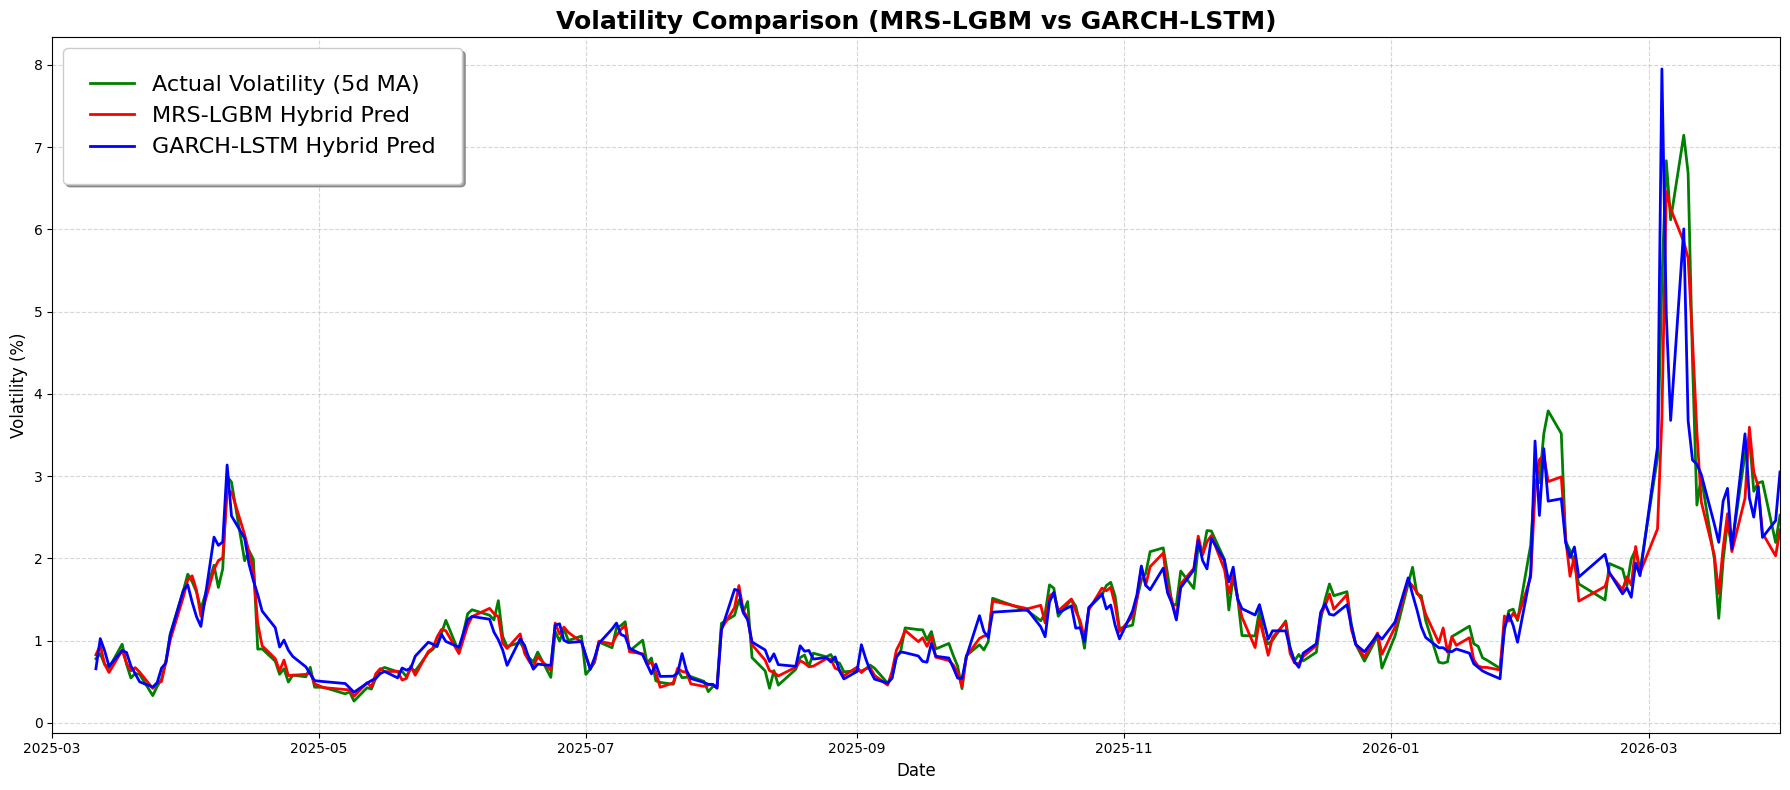


              [테스트 데이터셋 기준 모델 성능 비교표]
분석 모델 (Model) 오차제곱근 (RMSE) 평균절대오차 (MAE) 평균절대백분율오차 (MAPE)
   GARCH-LSTM       0.8203       0.5018           18.32%
     MRS-LGBM       0.4479       0.2957           12.09%


In [8]:
# 최종 결과 비교 시각화 그래프
plt.figure(figsize=(18, 8))
plt.plot(df_hybrid.index, df_hybrid['target'], label='Actual Volatility (5d MA)', color='green', linewidth=2)
plt.plot(df_hybrid.index, lgbm_hybrid_preds, label='MRS-LGBM Hybrid Pred', color='red', linewidth=2)
plt.plot(df_hybrid.index, garch_lstm_preds, label='GARCH-LSTM Hybrid Pred', color='blue', linewidth=2)

plt.xlim(pd.Timestamp('2025-03-01'), pd.Timestamp('2026-03-31'))
plt.title('Volatility Comparison (MRS-LGBM vs GARCH-LSTM)', fontsize=18, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Volatility (%)', fontsize=12)
plt.legend(loc='upper left', prop={'size': 16}, markerscale=1.5, borderpad=1.2, frameon=True, shadow=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()



# 테스트 데이터셋 기준 검증 성능 평가지표 비교
y_true = test_set['target'].values
X_test_lstm_scaled = scaler.transform(test_set[features_garch_lstm])
X_test_lstm_3d = X_test_lstm_scaled.reshape((X_test_lstm_scaled.shape[0], 1, X_test_lstm_scaled.shape[1]))

preds_dict = {
    'GARCH-LSTM': garch_lstm_model.predict(X_test_lstm_3d, verbose=0).flatten(),
    'MRS-LGBM': test_set['mrs_garch_vol'].values + residual_lgbm_model.predict(X_test_h)
}

performance_metrics = {
    '분석 모델 (Model)': [],
    '오차제곱근 (RMSE)': [],
    '평균절대오차 (MAE)': [],
    '평균절대백분율오차 (MAPE)': []
}

for name, preds in preds_dict.items():
    rmse = np.sqrt(mean_squared_error(y_true, preds))
    mae = mean_absolute_error(y_true, preds)
    mape = np.mean(np.abs((y_true - preds) / y_true)) * 100

    performance_metrics['분석 모델 (Model)'].append(name)
    performance_metrics['오차제곱근 (RMSE)'].append(f"{rmse:.4f}")
    performance_metrics['평균절대오차 (MAE)'].append(f"{mae:.4f}")
    performance_metrics['평균절대백분율오차 (MAPE)'].append(f"{mape:.2f}%")

df_comparison = pd.DataFrame(performance_metrics)
print("\n" + "=" * 75)
print("              [테스트 데이터셋 기준 모델 성능 비교표]")
print("=" * 75)
print(df_comparison.to_string(index=False))
print("=" * 75)
